In [1]:
import uproot
import pandas
import numpy as np
import os

import ipympl

from scipy import interpolate
import scipy

import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.colors as mplColors
from cycler import cycler

uproot.__version__

'5.0.8'

In [2]:
class StyleThing:
  def __init__(self, color, linestyle):
    self.col = color
    self.ls = linestyle
    
class MyStyleSet:
  def __init__(self, option = "nobles"):
    
    # medium types. these are what populate the other arrays 
    self.air = StyleThing('goldenrod', '-')
    
    self.lxe = StyleThing('darkviolet', '-')
    self.lxe2 = StyleThing('fuchsia', '-')

    self.cf4 = StyleThing('deepskyblue', '-')
    # self.cf4_2 = StyleThing('deepskyblue', '-')
    
    self.green = StyleThing('springgreen', '-')
    
    self.red = StyleThing('red', '-')
    
    self.test = StyleThing('#d94ff5', '-')
    
    # line styles
    self.line1 = "-"
    self.line2 = "--"
    self.line3 = "-."
    
    # all colors
    self.names = [x for x in self.__dict__.keys() if isinstance(self.__dict__[x], StyleThing)]
    self.allColsStr = [x.col for x in self.__dict__.values() if isinstance(x, StyleThing)]
    self.allColsObj = mplColors.to_rgba_array(self.allColsStr).reshape(1, -1, 4)
    
  def show(self):
    fig, ax = plt.subplots(figsize = (len(self.names)*1.5, 2))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.imshow(self.allColsObj, aspect=0.5)
    for i, (color, name) in enumerate(zip(self.allColsStr, self.names)):
      txt = f"{name} \n {color}"
      ax.text(i, 0, txt, ha='center', va='center')
    plt.show()
    return

ms = MyStyleSet()
    
    

['air', 'lxe', 'lxe2', 'cf4', 'green', 'red', 'test']


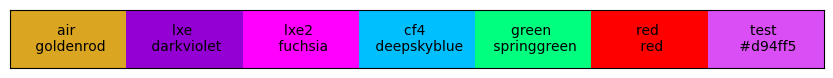

In [3]:
# show it off
ms.lxe.col
print(ms.names)

ms.show()

In [4]:
# # Define your custom style
# plt.rcParams['axes.titlesize'] = 20
# plt.rcParams['axes.labelsize'] = 14
# plt.rcParams['lines.linewidth'] = 2
# plt.rcParams['lines.markersize'] = 10
# plt.rcParams['xtick.labelsize'] = 12
# plt.rcParams['ytick.labelsize'] = 12

# # Define your custom colors
# plt.rcParams['axes.prop_cycle'] = plt.cycler(color=['r', 'g', 'b', 'y'])

# # plt.rcParams.keys()

# my_color = Style(color='r', linestyle='-')
# type(my_color)


In [5]:
## loading the data ##
rootPath1 = "../outputs_v1_noImaginary/"
rootPath2 = "../outputs_v2_allPhysics/"

opticsPath_g4 = "../g4PDEsim/dataOptics/"
scintPath_g4 = "../g4PDEsim/data_cf4_scint/"

In [6]:
pname = "No Window"
fileAir = uproot.open(os.path.join(rootPath2, "noWindow_air_N1e5_120-1050nm_0-85deg.root"))
fileCF4 = uproot.open(os.path.join(rootPath2, "noWindow_lcf4_N1e5_120-1050nm_0-85deg.root"))
filelxe = uproot.open(os.path.join(rootPath2, "noWindow_lxe_N1e5_120-1050nm_0-85deg.root"))

# pname = "Pure Si"
# fileAir = uproot.open(os.path.join(rootPath2, "noQuartz_air_N1e5_120-1050nm_0-85deg.root"))
# fileCF4 = uproot.open(os.path.join(rootPath2, "noQuartz_lcf4_N1e5_120-1050nm_0-85deg.root"))
# filelxe = uproot.open(os.path.join(rootPath2, "noQuartz_lxe_N1e5_120-1050nm_0-85deg.root"))

# pname = "No Passivation"
# fileAir = uproot.open(os.path.join(rootPath2, "onlyWindow_air_N1e5_120-1050nm_0-85deg.root"))
# fileCF4 = uproot.open(os.path.join(rootPath2, "onlyWindow_lcf4_N1e5_120-1050nm_0-85deg.root"))
# filelxe = uproot.open(os.path.join(rootPath2, "onlyWindow_lxe_N1e5_120-1050nm_0-85deg.root"))

# pname = "Complete"
# fileAir = uproot.open(os.path.join(rootPath2, "air_N1e5_120-1200nm_0-85deg.root"))
# fileCF4 = uproot.open(os.path.join(rootPath2, "lcf4_N1e5_120-1050nm_0-85deg.root"))
# filelxe = uproot.open(os.path.join(rootPath2, "lxe_N1e5_120-1050nm_0-85deg.root"))

ttAir = fileAir["simOutput"]
ttcf4 = fileCF4["simOutput"]
ttlxe = filelxe["simOutput"]

# Define the column names
column_names = ["fNphoton", "fPhotonWln", "fAngle", "fNonWindow", "fNonSurface", "fNonBulk", "fNinBulk"]
dfair = ttAir.arrays(library="pd").drop_duplicates()
print(dfair.head(5))
dfair["eff"] = dfair["fNinBulk"]/dfair["fNphoton"]

dfcf4 = ttcf4.arrays(library="pd").drop_duplicates()
dfcf4["eff"] = dfcf4["fNinBulk"]/dfcf4["fNphoton"]

dflxe = ttlxe.arrays(library="pd").drop_duplicates()
dflxe["eff"] = dflxe["fNinBulk"]/dflxe["fNphoton"]

# print(type(df))
# print(df.columns)

angles = dfair['fAngle'].unique()
print(angles)


   fNphoton  fPhotonWln     fAngle  fNonWindow  fNonSurface  fNonBulk   
0    100000  120.023425   0.000000           0        10623     42504  \
1    100000  120.023425  19.400007           0        10775     42644   
2    100000  120.023425  27.600007           0        10782     42829   
3    100000  120.023425  34.000003           0        11121     43033   
4    100000  120.023425  39.499997           0        11333     43086   

   fNinBulk  
0     46873  
1     46581  
2     46389  
3     45846  
4     45581  
[ 0.         19.40000717 27.60000725 34.00000311 39.49999688 44.39998923
 48.89999976 53.10000958 57.09999983 60.900257   64.59984549 68.10004466
 71.60024383 75.00017538 78.40010694 81.69977088 85.00000778]


[ 0.         19.40000717 27.60000725 34.00000311 39.49999688 44.39998923
 48.89999976 53.10000958 57.09999983 60.900257   64.59984549 68.10004466
 71.60024383 75.00017538 78.40010694 81.69977088 85.00000778]


<Figure size 400x400 with 0 Axes>

<Figure size 600x400 with 0 Axes>

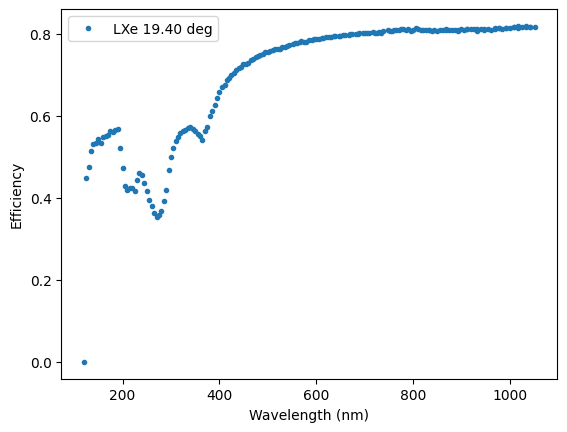

In [7]:
%matplotlib widget
%matplotlib inline

plt.figure(figsize=(4, 4))
angles = dflxe['fAngle'].unique()
dflxe_specific = dflxe[dflxe["fAngle"] == angles[1]]
print(angles)

fig = plt.figure(figsize=(6, 4))
dflxe_specific.plot(x='fPhotonWln', y='eff', marker=".", linestyle="None", label=f"LXe {angles[1]:0.2f} deg")
plt.xlabel('Wavelength (nm)')
plt.ylabel('Efficiency')
plt.show()
# plt.close('all')


/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_97922/2437301214.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('inferno')


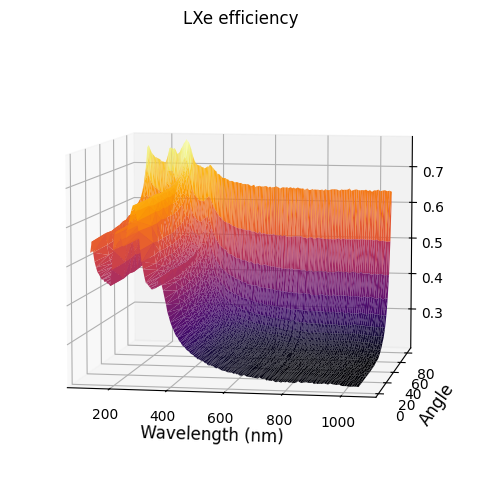

In [8]:
# %matplotlib widget
from mpl_toolkits.mplot3d import Axes3D
cmap = plt.cm.get_cmap('inferno')

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection='3d')

ax.plot_trisurf(dfair.fPhotonWln, dfair.fAngle, 1-dfair.eff, cmap=cmap, linewidth=0.2)

ax.set_title('LXe efficiency')
ax.set_xlabel('Wavelength (nm)', fontsize=12)
ax.set_ylabel('Angle', fontsize=12)
ax.set_zlabel('Efficiency', fontsize=12, labelpad=500)

# Enable interactive rotation
ax.view_init(elev=7, azim=-80)

plt.show()


In [9]:
import numpy as np
for df in [dfair, dfcf4, dflxe]:
  print(df['fAngle'].unique()[0])
  angles = df["fAngle"].unique()
  # print(len())
  index = np.abs(angles - 60).argmin()
  print(index)
  print(df["fAngle"].unique()[index])

# Example array
arr = np.array([1, 3, 5, 7, 9])

# Number to find the closest entry to
num = 6

# Find the index of the closest entry
closest_index = np.abs(arr - num).argmin()

# Get the closest entry
closest_entry = arr[closest_index]

print(closest_entry)  # Output: 7
  
closestAngle = lambda df, angle: df["fAngle"].unique()[np.abs(df["fAngle"].unique() - angle).argmin()]
closestAngle(dfair, 60)



0.0
9
60.90025700225034
0.0
9
60.90025700225034
0.0
9
60.90025700225034
5


60.90025700225034

In [10]:
## picking zero degrees
%matplotlib inline
wl = "fPhotonWln" # for shorthand
getAngle = 0
dfAir_a0 = dfair[dfair["fAngle"] == closestAngle(dfair, getAngle)].drop_duplicates(subset="fPhotonWln")
dfcf4_a0 = dfcf4[dfcf4["fAngle"] == closestAngle(dfcf4, getAngle)].drop_duplicates(subset="fPhotonWln")
dflxe_a0 = dflxe[dflxe["fAngle"] == closestAngle(dflxe, getAngle)].drop_duplicates(subset="fPhotonWln")

getAngle = 60
dfAir_aS = dfair[(dfair["fAngle"] == closestAngle(dfair, getAngle)) & (dfair["fPhotonWln"] > 300)].drop_duplicates(subset="fPhotonWln")
dfcf4_aS = dfcf4[(dfcf4["fAngle"] == closestAngle(dfcf4, getAngle)) & (dfcf4["fPhotonWln"] > 300)].drop_duplicates(subset="fPhotonWln")
dflxe_aS = dflxe[(dflxe["fAngle"] == closestAngle(dflxe, getAngle)) & (dflxe["fPhotonWln"] > 300)].drop_duplicates(subset="fPhotonWln")

## picking LXe values
closest_lxeScint = dfAir_a0[wl].values[np.abs(dfAir_a0[wl].values - 175).argmin()]
print(closest_lxeScint)

dfAir_175 = dfair[dfair["fPhotonWln"] == closest_lxeScint].drop_duplicates(subset="fAngle")
dflxe_175 = dflxe[dflxe["fPhotonWln"] == closest_lxeScint].drop_duplicates(subset="fAngle")

closest_400 = dfAir_a0[wl].values[np.abs(dfAir_a0[wl].values - 400).argmin()]
print(closest_400)

dfAir_400 = dfair[dfair["fPhotonWln"] == closest_400].drop_duplicates(subset="fAngle")
dflxe_400 = dflxe[dflxe["fPhotonWln"] == closest_400].drop_duplicates(subset="fAngle")

## picking CF4 values
closest_300 = dfAir_a0[wl].values[np.abs(dfAir_a0[wl].values - 300).argmin()]
print(closest_300)

dfAir_300 = dfair[dfair["fPhotonWln"] == closest_300].drop_duplicates(subset="fAngle")
dfcf4_300 = dfcf4[dfcf4["fPhotonWln"] == closest_300].drop_duplicates(subset="fAngle")

## picking 650 nm
closest_650 = dfAir_a0[wl].values[np.abs(dfAir_a0[wl].values - 650).argmin()]
print(closest_650)

dfAir_650 = dfair[dfair["fPhotonWln"] == closest_650].drop_duplicates(subset="fAngle")
dfcf4_650 = dfcf4[dfcf4["fPhotonWln"] == closest_650].drop_duplicates(subset="fAngle")



174.87193008913997
399.9490272038717
300.2038702983056
649.1319289696347


In [11]:
smoothSigma = 3
gsmooth = lambda x: scipy.ndimage.gaussian_filter1d(input = x, sigma = smoothSigma)

# vs wavelength
f_air_0 = interpolate.interp1d(x = np.array(dfAir_a0[wl]), y = gsmooth(np.array(dfAir_a0["eff"])), kind = "cubic")
f_cf4_0 = interpolate.interp1d(x = np.array(dfcf4_a0[wl]), y = gsmooth(np.array(dfcf4_a0["eff"])), kind = "cubic")
f_lxe_0 = interpolate.interp1d(x = np.array(dflxe_a0[wl]), y = gsmooth(np.array(dflxe_a0["eff"])), kind = "cubic")

# vs angle (fixed lambda)
f_air_175 = interpolate.interp1d(x=np.array(dfAir_175["fAngle"]), y=np.array(dfAir_175["eff"]), kind="cubic")
f_lxe_175 = interpolate.interp1d(x=np.array(dflxe_175["fAngle"]), y=np.array(dflxe_175["eff"]), kind="cubic")
f_air_400 = interpolate.interp1d(x=np.array(dfAir_400["fAngle"]), y=np.array(dfAir_400["eff"]), kind="cubic")
f_lxe_400 = interpolate.interp1d(x=np.array(dflxe_400["fAngle"]), y=np.array(dflxe_400["eff"]), kind="cubic")

f_air_300 = interpolate.interp1d(x=np.array(dfAir_300["fAngle"]), y=np.array(dfAir_300["eff"]), kind="cubic")
f_air_650 = interpolate.interp1d(x=np.array(dfAir_650["fAngle"]), y=np.array(dfAir_650["eff"]), kind="cubic")
f_cf4_650 = interpolate.interp1d(x=np.array(dfcf4_650["fAngle"]), y=np.array(dfcf4_650["eff"]), kind="cubic")


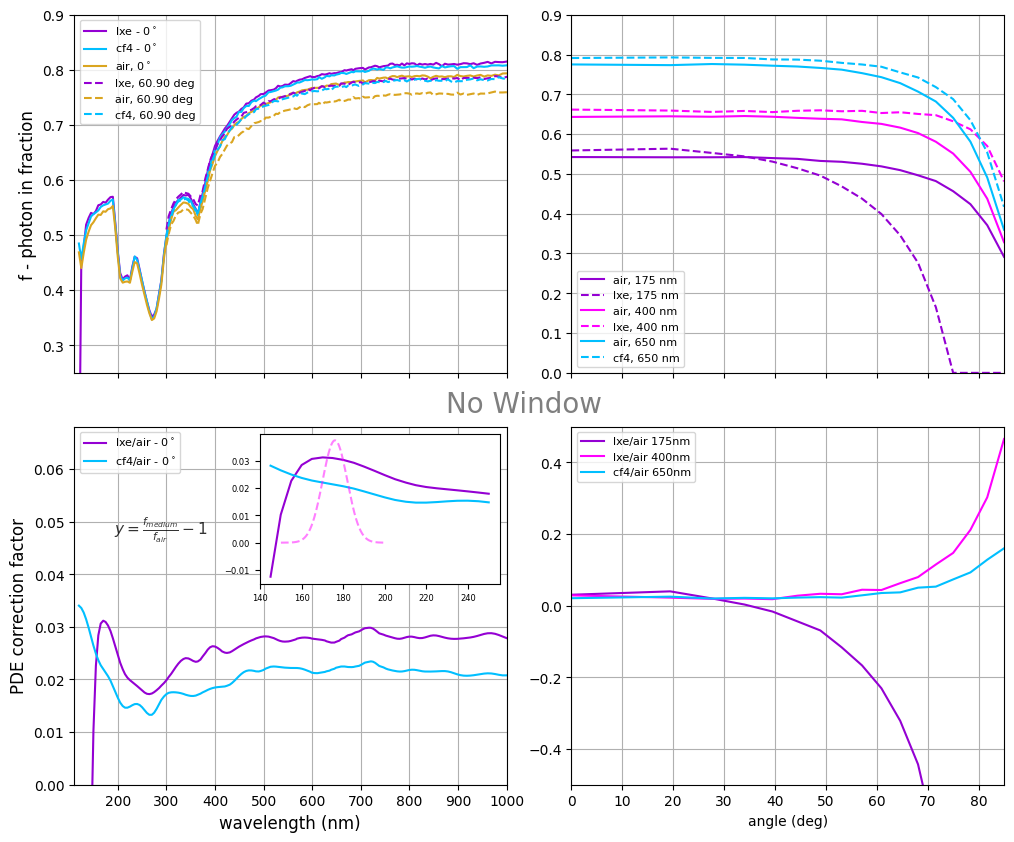

In [12]:
# Plot the data frames on the same canvas
fig, ((ax1, ax3), (ax2, ax4)) = plt.subplots(2, 2, sharex='col', figsize=(12, 10))

## -- top left
dflxe_a0.plot(x="fPhotonWln", y="eff", kind="line", label="lxe - 0$^\circ$", color = ms.lxe.col, ax = ax1)
dfcf4_a0.plot(x="fPhotonWln", y="eff", kind="line", label="cf4 - 0$^\circ$", color = ms.cf4.col, ax = ax1)
dfAir_a0.plot(x="fPhotonWln", y="eff", kind="line", label='air, 0$^\circ$', color = ms.air.col, ax = ax1)

# ax1p = ax1.twinx()
dflxe_aS.plot(x="fPhotonWln", y="eff", kind="line", linestyle = "--", color = ms.lxe.col, label=f'lxe, {dflxe_aS["fAngle"].iloc[0]:0.2f} deg', ax = ax1)
dfAir_aS.plot(x="fPhotonWln", y="eff", kind="line", linestyle = "--", color = ms.air.col, label=f'air, {dfAir_aS["fAngle"].iloc[0]:0.2f} deg', ax = ax1)
dfcf4_aS.plot(x="fPhotonWln", y="eff", kind="line", linestyle = "--", color = ms.cf4.col, label=f'cf4, {dfcf4_aS["fAngle"].iloc[0]:0.2f} deg', ax = ax1)

a1Min = min(dfcf4_a0["eff"].min(), dfAir_a0["eff"].min())

ax1.set_ylim(0.25, 0.9)
ax1.set_xlim(110, 1000)

#ax2 bottom left - correction
xCF4 = np.array(dfcf4_a0["fPhotonWln"])
xwl = np.arange(min(xCF4), max(xCF4), 10)
ax2.plot(xCF4, f_lxe_0(xCF4)/f_air_0(xCF4)-1, color = ms.lxe.col, label=f"lxe/air - 0$^\circ$")
ax2.plot(xCF4, f_cf4_0(xCF4)/f_air_0(xCF4)-1, color = ms.cf4.col, label="cf4/air - 0$^\circ$")
a2Max = 2.* max(max(f_lxe_0(xCF4)/f_air_0(xCF4)-1), max(f_cf4_0(xCF4)/f_air_0(xCF4)-1))
ax2.set_ylim(0, a2Max)

# ax 3 - eff vs angle (top right)
dfAir_175.plot(x="fAngle", y="eff", kind="line", color = ms.lxe.col, linestyle = ms.line1, label='air, 175 nm', ax = ax3)
dflxe_175.plot(x="fAngle", y="eff", kind="line", color = ms.lxe.col, linestyle = ms.line2, label="lxe, 175 nm", ax = ax3)

dfAir_400.plot(x="fAngle", y="eff", kind="line", color = ms.lxe2.col, linestyle = ms.line1, label='air, 400 nm', ax = ax3)
dflxe_400.plot(x="fAngle", y="eff", kind="line", color = ms.lxe2.col, linestyle = ms.line2, label="lxe, 400 nm", ax = ax3)

dfAir_650.plot(x="fAngle", y="eff", kind="line", color= ms.cf4.col, linestyle = ms.line1, label='air, 650 nm', ax = ax3)
dfcf4_650.plot(x="fAngle", y="eff", kind="line", color= ms.cf4.col, linestyle = ms.line2, label="cf4, 650 nm", ax = ax3)
ax3.set_ylim(0, 0.9)
ax3.set_xlim(0, 85)

# ax4 bottom right - angle correction
xAngLxe = dflxe_175["fAngle"]
ax4.plot(xAngLxe, f_lxe_175(xAngLxe)/f_air_175(xAngLxe)-1, color = ms.lxe.col, label="lxe/air 175nm")
ax4.plot(xAngLxe, f_lxe_400(xAngLxe)/f_air_400(xAngLxe)-1, color = ms.lxe2.col, label="lxe/air 400nm")
ax4.plot(xAngLxe, f_cf4_650(xAngLxe)/f_air_650(xAngLxe)-1, color = ms.cf4.col, label="cf4/air 650nm")
ax4.set_ylim(-0.5, 0.5)


#### formatting
fnameFront = (fileAir.file_path.split("/")[-1]).split("_")[0]
# fig.suptitle(f"PDE correction: {fnameFront}", fontsize = 20)

fs = 12
fsleg = 8
ax1.set_ylabel("f - photon in fraction", fontsize = fs)
ax1.set_xlabel("wavelength (nm)", fontsize = fs)

ax1.legend(loc = "upper left", fontsize = fsleg)

ax2.text(0.2, 0.7, r"$y = \frac{f_{medium}}{f_{air}} - 1$", transform=ax2.transAxes, ha='center', fontsize=fsleg+3, alpha = 0.8)

ax2.set_ylabel("PDE correction factor", fontsize = fs)
ax2.set_xlabel("wavelength (nm)", fontsize = fs)
ax2.legend(loc="upper left", fontsize = fsleg)

# ax3.set_ylabel("fraction of photons in")
ax3.set_xlabel("angle (deg)")
ax3.legend(fontsize = fsleg)

ax4.legend(fontsize = fsleg)
# ax4.set_ylabel("PDE correction factor")
ax4.set_xlabel("angle (deg)")

for ax in [ax1, ax2, ax3, ax4]:
    ax.grid(True)

# Add "preliminary" text at 45 degrees
fig.text(0.5, 0.49, pname, alpha=0.5, rotation=0, ha='center', va='center', fontsize=20)

# zoom in must be done at bottom
lxeS_x = np.linspace(150, 200, 1000)
sigma = 14 / (2 * np.sqrt(2 * np.log(2)))  # Standard deviation of the Gaussian
lxeS_y = np.exp(-(lxeS_x - 176)**2 / (2 * sigma**2))

axins = inset_axes(ax2, width=2.4, height=1.5, loc='upper right', bbox_to_anchor=(1, 1), bbox_transform=ax2.transAxes)
zoom_xcf4 = xCF4[np.where((xCF4 > 140) & (xCF4 < 250))]
axins.plot(zoom_xcf4, f_lxe_0(zoom_xcf4)/f_air_0(zoom_xcf4)-1, color = ms.lxe.col)
axins.plot(zoom_xcf4, f_cf4_0(zoom_xcf4)/f_air_0(zoom_xcf4)-1, color = ms.cf4.col)
axins.plot(lxeS_x, 1.2*lxeS_y * max(f_lxe_0(zoom_xcf4)/f_air_0(zoom_xcf4)-1)/max(lxeS_y), alpha = 0.5, color = ms.lxe2.col, linestyle = ms.line2)
# axins.set_xlim(140, 250)
# axins.set_ylim(-0.05, 1)
axins.tick_params(axis='x', labelsize=6)
axins.tick_params(axis='y', labelsize=6)

# Show the plot
plt.subplots_adjust(hspace=0.15, wspace = 0.15)
# plt.tight_layout()
plt.show()

In [13]:
# import numpy as np

def fresnel_equations(n1, n2, theta_i):
  """
  Calculate the reflection and transmission coefficients for S and P polarized light using the Fresnel equations.

  Parameters:
  - n1: refractive index of the incident medium
  - n2: refractive index of the transmitted medium
  - theta_i: angle of incidence (in radians)

  Returns:
  - rs: reflection coefficient for S polarized light
  - rp: reflection coefficient for P polarized light
  - ts: transmission coefficient for S polarized light
  - tp: transmission coefficient for P polarized light
  """

  # Calculate the angle of transmission
  theta_t = np.arcsin((n1 / n2) * np.sin(theta_i))

  # Calculate the reflection coefficients
  rs = (n1 * np.cos(theta_i) - n2 * np.cos(theta_t)) / (n1 * np.cos(theta_i) + n2 * np.cos(theta_t))
  rp = (n2 * np.cos(theta_i) - n1 * np.cos(theta_t)) / (n2 * np.cos(theta_i) + n1 * np.cos(theta_t))

  # Calculate the transmission coefficients
  ts = 2 * n1 * np.cos(theta_i) / (n1 * np.cos(theta_i) + n2 * np.cos(theta_t))
  tp = 2 * n1 * np.cos(theta_i) / (n2 * np.cos(theta_i) + n1 * np.cos(theta_t))

  return rs, rp, ts, tp


def fresnel_Rboth(n1, n2, theta):
  
  rs, rp, ts, tp = fresnel_equations(n1, n2, theta)
  
  Rs = np.abs(rs)**2
  Rp = np.abs(rp)**2
  
  return Rp, Rs

def fresnel_Ref(n1, n2, theta):
  
  rs, rp, ts, tp = fresnel_equations(n1, n2, theta)
  
  Rs = np.abs(rs)**2
  Rp = np.abs(rp)**2
  
  return (Rs + Rp)/2.



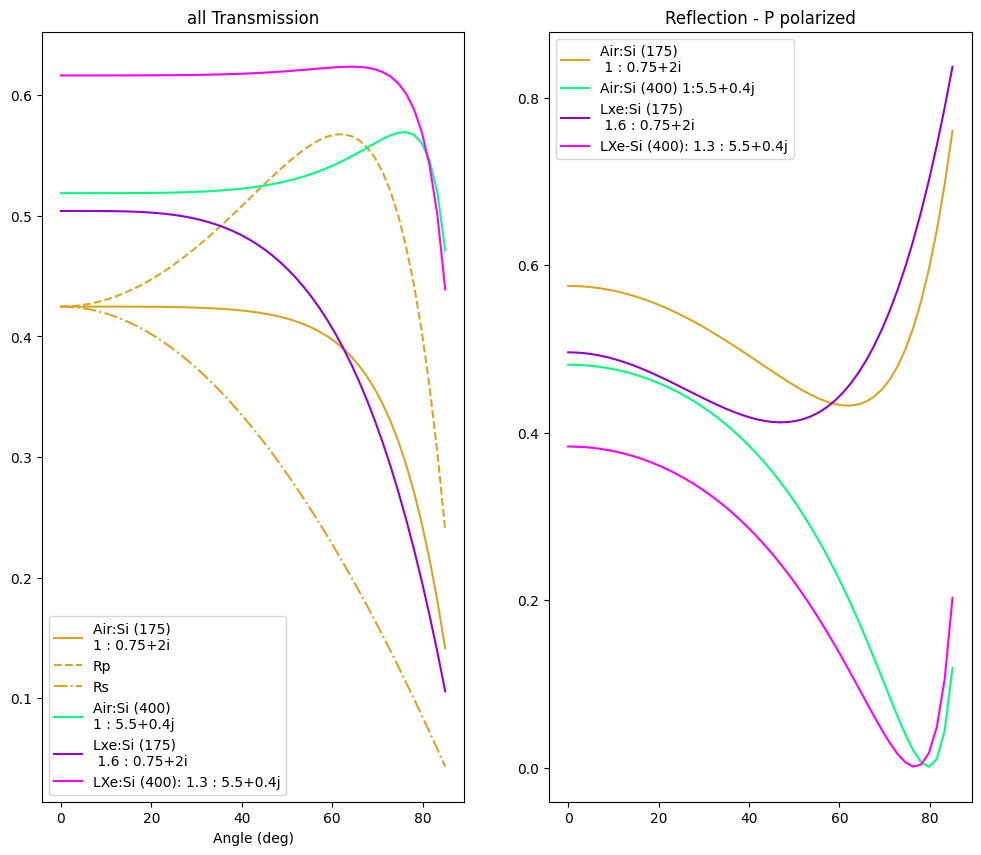

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (12, 10))


xAngle = np.linspace(0, 85/180 * np.pi, 50)

xnFrac = np.linspace(1.01, 4, 50)

# ax1.plot(xAngle*180/np.pi, 1-fresnel_Ref(n1 = 1, n2 = 4, theta = xAngle), label = "1 :4")

# ax1.plot(xAngle*180/np.pi, 1-fresnel_Ref(n1 = 1.5, n2 = 4, theta = xAngle), label = "1.5 : 4")

# ax1.plot(xAngle*180/np.pi, 1-fresnel_Ref(n1 = 2, n2 = 5, theta = xAngle), label = "1.5 : 4")

ax1.plot(xAngle*180/np.pi, 1-fresnel_Ref(n1 = 1.0, n2 = 0.75+2j, theta = xAngle), color = ms.air.col, label = "Air:Si (175)\n1 : 0.75+2i")
ax1.plot(xAngle*180/np.pi, 1-fresnel_Rboth(n1 = 1.0, n2 = 0.75+2j, theta = xAngle)[0], color = ms.air.col, linestyle = ms.line2, label = "Rp")
ax1.plot(xAngle*180/np.pi, 1-fresnel_Rboth(n1 = 1.0, n2 = 0.75+2j, theta = xAngle)[1], color = ms.air.col, linestyle = ms.line3, label = "Rs")

ax1.plot(xAngle*180/np.pi, 1-fresnel_Ref(n1 = 1.0, n2 = 5.5+0.39j, theta = xAngle), color = ms.green.col, label = "Air:Si (400)\n1 : 5.5+0.4j")

ax1.plot(xAngle*180/np.pi, 1-fresnel_Ref(n1 = 1.6, n2 = 0.75+2j, theta = xAngle), color = ms.lxe.col, label = "Lxe:Si (175)\n 1.6 : 0.75+2i")

ax1.plot(xAngle*180/np.pi, 1-fresnel_Ref(n1 = 1.3, n2 = 5.5+0.39j, theta = xAngle), color = ms.lxe2.col, label = "LXe:Si (400): 1.3 : 5.5+0.4j")

ax1.legend()
ax1.set_xlabel("Angle (deg)")
ax1.set_title("all Transmission")

ax2.set_title("Reflection - P polarized")
ax2.plot(xAngle*180/np.pi, fresnel_Rboth(n1 = 1.0, n2 = 0.75+2j, theta = xAngle)[0], color = ms.air.col, label = "Air:Si (175)\n 1 : 0.75+2i")

ax2.plot(xAngle*180/np.pi, fresnel_Rboth(n1 = 1., n2 = 5.5+0.39j, theta = xAngle)[0], color = ms.green.col, label = "Air:Si (400) 1:5.5+0.4j")

ax2.plot(xAngle*180/np.pi, fresnel_Rboth(n1 = 1.6, n2 = 0.75+2j, theta = xAngle)[0], color = ms.lxe.col, label = "Lxe:Si (175)\n 1.6 : 0.75+2i")

# ax2.plot(xAngle*180/np.pi, fresnel_Rboth(n1 = 1.6, n2 = 0.75+2j, theta = xAngle)[0], label = "Lxe:Si (175)\n 1.6 : 0.75+2i")

ax2.plot(xAngle*180/np.pi, fresnel_Rboth(n1 = 1.3, n2 = 5.5+0.39j, theta = xAngle)[0], color = ms.lxe2.col, label = "LXe-Si (400): 1.3 : 5.5+0.4j")


ax2.legend()

plt.show()

In [15]:
# # print(type(tt))
# # print(tt.keys())
# # np = tt.arrays("fNphoton")
# # tt.num_entries


# wlPDE, pde = np.loadtxt(os.path.join(opticsPath, "SiPMeff_Ham_5V.dat"), skiprows=1, unpack = True)
# pde *= 1/100

# start = 9
# pdeScaledUp = pde[start:]/fairEff_0(wlPDE[start:])
# pdeScaledBack = pdeScaledUp*fcf4Eff_0(wlPDE[start:])  

# # are the optics dominated by the thin film or the bulk                         

# plt.plot(wlPDE, pde, label = "regular PDE")
# plt.plot(wlPDE[start:], pdeScaledUp, label = "scaled up")
# plt.plot(wlPDE[start:], pdeScaledBack, label = "after CF4 optics")
# plt.legend()

# plt.show()

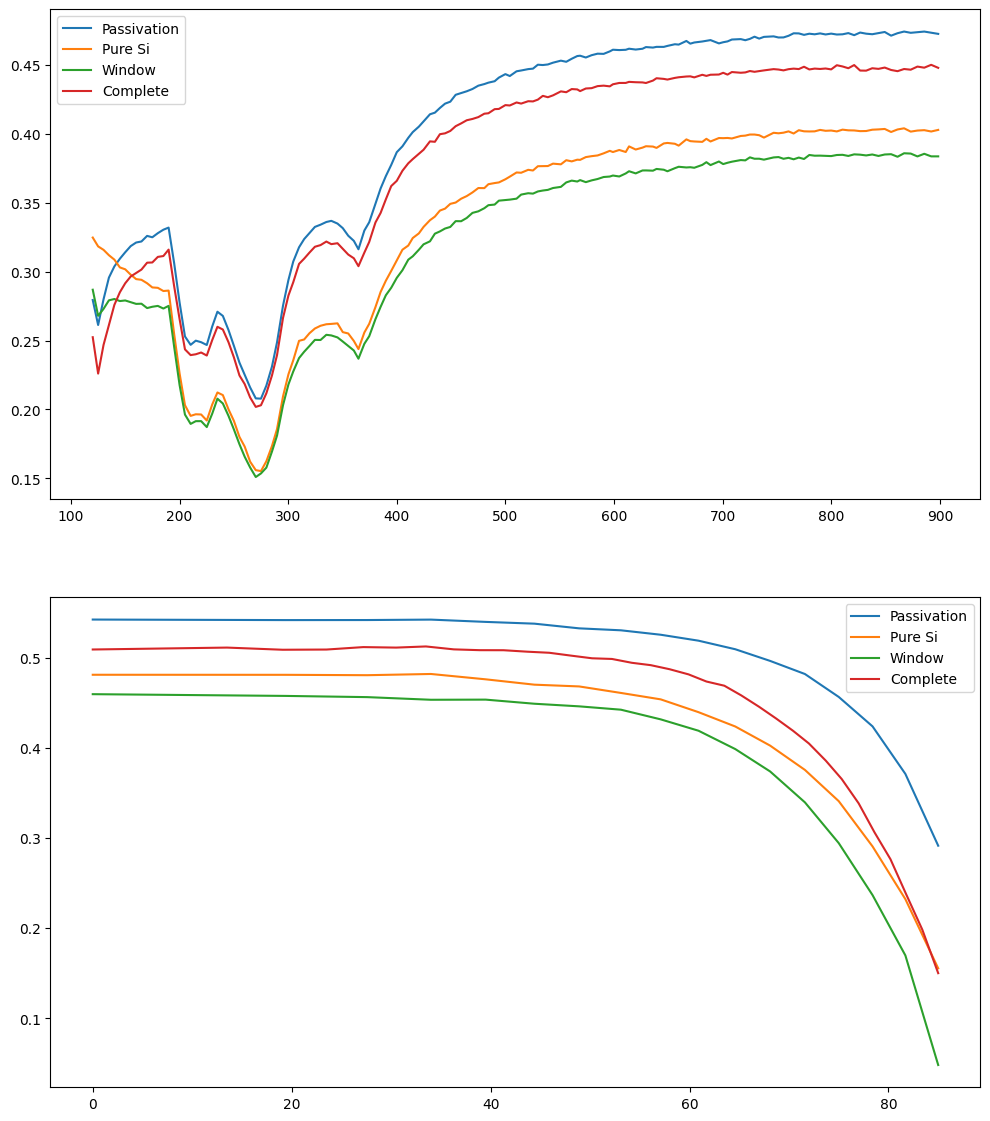

In [23]:
## Opening All the air files
pnames = ["Passivation"]
fileAir1 = uproot.open(os.path.join(rootPath2, "noWindow_air_N1e5_120-1050nm_0-85deg.root"))
filelxe1 = uproot.open(os.path.join(rootPath2, "noWindow_lxe_N1e5_120-1050nm_0-85deg.root"))
tt1 = fileAir1["simOutput"]
ttxe1 = filelxe1["simOutput"]

pnames.append("Pure Si")
fileAir2 = uproot.open(os.path.join(rootPath2, "noQuartz_air_N1e5_120-1050nm_0-85deg.root"))
filelxe2 = uproot.open(os.path.join(rootPath2, "noQuartz_lxe_N1e5_120-1050nm_0-85deg.root"))
tt2 = fileAir2["simOutput"]
ttxe2 = filelxe2["simOutput"]

pnames.append("Window")
fileAir3 = uproot.open(os.path.join(rootPath2, "onlyWindow_air_N1e5_120-1050nm_0-85deg.root"))
filelxe3 = uproot.open(os.path.join(rootPath2, "onlyWindow_lxe_N1e5_120-1050nm_0-85deg.root"))
tt3 = fileAir3["simOutput"]
ttxe3 = filelxe3["simOutput"]

pnames.append("Complete")
fileAir4 = uproot.open(os.path.join(rootPath2, "air_N1e5_120-1200nm_0-85deg.root"))
filelxe4 = uproot.open(os.path.join(rootPath2, "lxe_N1e5_120-1050nm_0-85deg.root"))
tt4 = fileAir4["simOutput"]
ttxe4 = filelxe4["simOutput"]

ttList = [tt1, tt2, tt3, tt4]
ttxeList = [ttxe1, ttxe2, ttxe3, ttxe4]
dfList = [tt.arrays(library="pd").drop_duplicates() for tt in ttList]
dfXeList = [tt.arrays(library="pd").drop_duplicates() for tt in ttxeList]

for df in dfList+dfXeList:
  df["eff"] = df["fNinBulk"]/df["fNphoton"]

getAngle = 15
dfAngleList = [df[df["fAngle"] == closestAngle(df, getAngle)].drop_duplicates(subset="fPhotonWln") for df in dfList]
dfXeAngleList = [df[df["fAngle"] == closestAngle(df, getAngle)].drop_duplicates(subset="fPhotonWln") for df in dfXeList]

getWlen = 175
closestWlen = lambda df, wlen: df["fPhotonWln"].unique()[np.abs(df["fPhotonWln"].unique() - wlen).argmin()]
dfWlenList = [df[df["fPhotonWln"] == closestWlen(df, getWlen)].drop_duplicates(subset="fAngle") for df in dfList]

# Plot the data frames on the same canvas
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 14))
bottomLim = 120
topLim = 900

## -- top left
for df, name in zip(dfAngleList, pnames):
  x = df["fPhotonWln"].values
  map = np.where((x > bottomLim) & (x < topLim))
  x = x[map]
  y = df["eff"].values[map]
  y *= 0.6
  ax1.plot(x, y, label = name)
  
for df, name in zip(dfWlenList, pnames):
  x = df["fAngle"].values
  # map = np.where((x > bottomLim) & (x < topLim))
  # x = x[map]
  y = df["eff"].values
  # y *= 0.6
  ax2.plot(x, y, label = name)

# ax1.plot(dfAngleList[0]["fPhotonWln"], dfAngleList[0]["eff"], label = pnames[0], color = ms.air.col)

ax1.legend()
ax2.legend()
# ax1.set_ylim(0.25, 0.9)
# ax1.set_xlim(110, 280)

plt.show()